# Assignment 2: My Spatial Databases

**Course:** Data Science and Algorithms (CS BIT)
**Topic:** Building an in-memory spatial database for Points of Interest (POI)
**Dataset:** `Assignment2-2012_BIT_POI.csv` (POIs around Beijing Institute of Technology)

## Goal
Build an in-memory spatial database that supports:
1. **Range queries** (rectangle or point+radius)
2. **Nearest Neighbor queries**

We compare query performance **with** and **without** a spatial index, and answer the two questions in the assignment.

## Method: Grid-based Spatial Indexing
We follow the **Grid-based Spatial Indexing** method presented in the lecture slides (DSA Chapter 3.4.2, *Space-partition-based Index*):

> *"Partition the space into disjoint and uniform grids. Build inverted index between each grid and the points in the grid."*
> *"Easy to implement and understand. Very efficient for processing range and nearest queries."*

All algorithms are implemented from scratch, without relying on any pre-built spatial library.

---

> **Note for Google Colab:** upload the dataset `Assignment2-2012_BIT_POI.csv` to the Colab session before running the notebook, or change the `FILE_PATH` variable below to point to its location.


## 1. Setup and Imports

In [1]:
# Standard library
import csv
import math
import re
import time
from collections import defaultdict

# Scientific stack
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Reproducibility and display
np.random.seed(42)
plt.rcParams['figure.dpi'] = 100
plt.rcParams['figure.figsize'] = (10, 8)

# Dataset: 2,159 points of interest around the BIT campus (WGS84).
# Runs as-is locally or on Colab: if the file is missing it is downloaded from the repo.
import os
import urllib.request

FILE_PATH = 'data/Assignment2-2012_BIT_POI.csv'
DATA_URL = 'https://raw.githubusercontent.com/maximofox338/Spatial-Indexing/main/data/Assignment2-2012_BIT_POI.csv'
if not os.path.exists(FILE_PATH):
    os.makedirs('data', exist_ok=True)
    urllib.request.urlretrieve(DATA_URL, FILE_PATH)

print('Libraries loaded successfully.')


Libraries loaded successfully.


## 2. Dataset Exploration

The POI dataset contains points around the Beijing Institute of Technology (BIT). Each row describes one Point of Interest with its name, coordinates in the WGS-84 system, and a hierarchical type code.


In [2]:
df = pd.read_csv(FILE_PATH)
print(f'Number of POIs: {len(df)}')
print(f'Columns: {df.columns.tolist()}')
print()
print('Sample rows:')
df.head()


Number of POIs: 2159
Columns: ['name', 'wgs_lat', 'wgs_lng', 'type_code', 'base_type', 'sub_type', 'category']

Sample rows:


,name,wgs_lat,wgs_lng,type_code,base_type,sub_type,category
0,寰太大厦员工餐厅,39.958029,116.317624,50100,餐饮服务,中餐厅,中餐厅
1,一手店（北三环西路辅路）,39.965707,116.313841,50000,餐饮服务,餐饮相关场所,餐饮相关
2,三博冒菜馆,39.966749,116.317380,50100,餐饮服务,中餐厅,中餐厅
3,奇豆の恋,39.967321,116.318733,50700,餐饮服务,冷饮店,冷饮店
4,茶真乡,39.953802,116.316822,50400,餐饮服务,休闲餐饮场所,休闲餐饮场所


In [3]:
print('Coordinate ranges:')
print(f'  Latitude : {df["wgs_lat"].min():.6f}  to  {df["wgs_lat"].max():.6f}')
print(f'  Longitude: {df["wgs_lng"].min():.6f}  to  {df["wgs_lng"].max():.6f}')
print()
print('Distribution of the main type categories (base_type):')
print(df['base_type'].value_counts().head(10))


Coordinate ranges:
  Latitude : 39.953008  to  39.967978
  Longitude: 116.297009  to  116.319967

Distribution of the main type categories (base_type):
base_type
公司企业         490
餐饮服务         282
科教文化服务       269
生活服务         258
购物服务         224
商务住宅         170
政府机构及社会团体    115
金融保险服务        96
公共设施          81
体育休闲服务        60
Name: count, dtype: int64


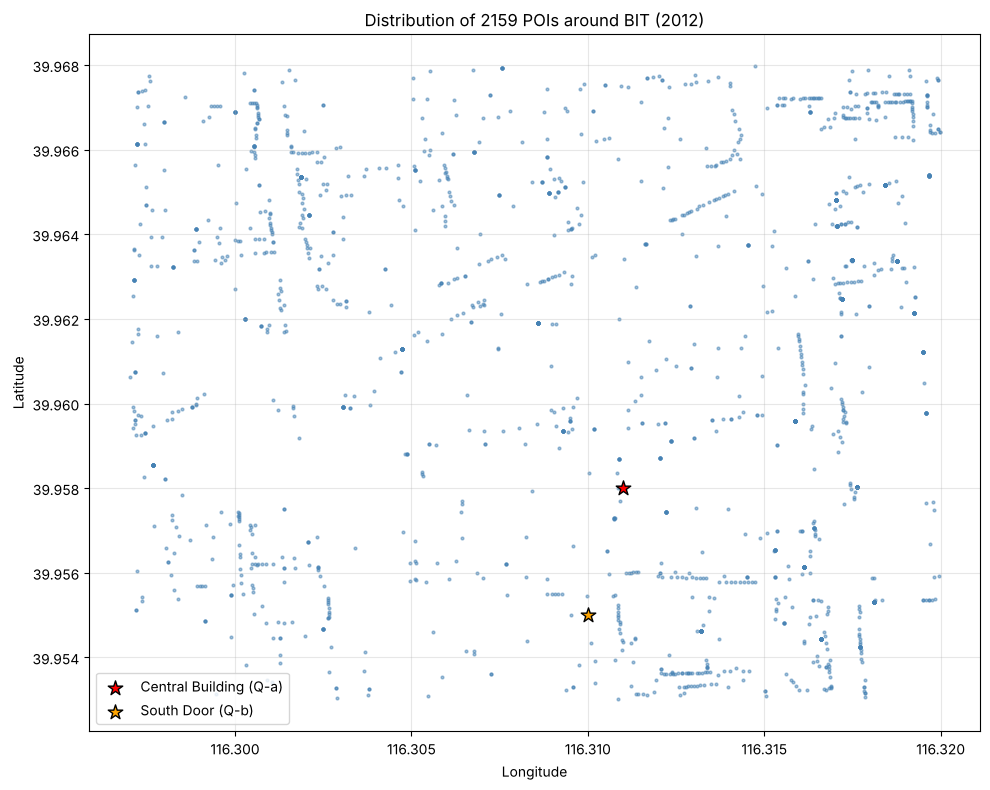

In [4]:
# Quick scatter plot of all POIs
fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(df['wgs_lng'], df['wgs_lat'], s=4, alpha=0.5, c='steelblue')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title(f'Distribution of {len(df)} POIs around BIT (2012)')
ax.grid(True, alpha=0.3)

# Mark the two reference points used in the questions
ax.scatter([116.311], [39.958], c='red', s=120, marker='*',
           edgecolor='black', label='Central Building (Q-a)', zorder=5)
ax.scatter([116.310], [39.955], c='orange', s=120, marker='*',
           edgecolor='black', label='South Door (Q-b)', zorder=5)
ax.legend()
plt.tight_layout()
plt.show()


## 3. Distance Function — Haversine

Because POIs are expressed in geographic coordinates (latitude/longitude), we cannot use plain Euclidean distance on the raw values: one degree of longitude is not the same physical distance as one degree of latitude, and both vary with position. The assignment FAQ points to the **haversine** formula for this exact reason.

$$
d = 2R \cdot \arcsin\!\left(\sqrt{\sin^2\!\left(\tfrac{\Delta\varphi}{2}\right) + \cos\varphi_1 \cos\varphi_2 \sin^2\!\left(\tfrac{\Delta\lambda}{2}\right)}\right)
$$

where $R \approx 6{,}371{,}000$ m is the Earth's radius and $\varphi, \lambda$ are latitude and longitude in radians.


In [5]:
EARTH_RADIUS_M = 6_371_000.0

def haversine(lat1, lon1, lat2, lon2):
    """Return distance in meters between two WGS-84 points."""
    phi1 = math.radians(lat1)
    phi2 = math.radians(lat2)
    dphi = math.radians(lat2 - lat1)
    dlam = math.radians(lon2 - lon1)
    a = math.sin(dphi / 2) ** 2 + math.cos(phi1) * math.cos(phi2) * math.sin(dlam / 2) ** 2
    return 2 * EARTH_RADIUS_M * math.asin(math.sqrt(a))

# Sanity check: distance between Central Building and South Door
d = haversine(39.958, 116.311, 39.955, 116.310)
print(f'Distance Central Building - South Door: {d:.1f} m')


Distance Central Building - South Door: 344.3 m


## 4. `IndexBuilding` — Grid-based Spatial Index

Following slide 48 of Chapter 3, the index is built in two steps:

1. **Partition the space** into a grid of disjoint and uniform cells.
2. **Build an inverted index** `cell -> list of points in that cell`.

### Design decisions
- The grid covers the minimum bounding rectangle of all POIs, with a small margin so boundary points are safely contained.
- The cell size is expressed in **degrees** but chosen so each cell is roughly a square of side `CELL_SIZE_METERS` in the study area. This keeps cells physically uniform.
- The index is stored as a `dict` keyed by `(row, col)` tuples — an inverted index exactly as shown in the slide.

The cell-size parameter controls a classic space / time trade-off:
- Smaller cells → fewer points per cell → faster queries, bigger index.
- Larger cells → more points per cell → slower queries, smaller index.

Slide 51 flags this explicitly: *"Index size could be big. Difficult to deal with unbalanced data."*


In [6]:
# Size of each grid cell, in meters. 100 m is a good default for this dataset:
# the study area is roughly 2 km x 1.5 km and contains ~2k points.
CELL_SIZE_METERS = 100


def _meters_to_degrees(meters, ref_lat):
    """Convert a metric distance into degrees of latitude and longitude
    at a given reference latitude."""
    dlat = meters / 111_320.0                       # 1 deg lat ≈ 111,320 m
    dlng = meters / (111_320.0 * math.cos(math.radians(ref_lat)))
    return dlat, dlng


def IndexBuilding(file_path, cell_size_m=CELL_SIZE_METERS):
    """Build an in-memory grid-based spatial index for a POI CSV file.

    Returns a dict containing:
        - 'points'   : list of POI records
        - 'grid'     : inverted index  (row, col) -> list of point indices
        - 'min_lat', 'min_lng', 'max_lat', 'max_lng' : bounding box
        - 'cell_dlat', 'cell_dlng' : cell size in degrees
        - 'n_rows', 'n_cols' : grid dimensions
        - 'cell_size_m' : requested cell size in meters
    """
    # --- 1. Load all points from the CSV ---
    points = []
    with open(file_path, 'r', encoding='utf-8') as f:
        reader = csv.DictReader(f)
        for row in reader:
            try:
                lat = float(row['wgs_lat'])
                lng = float(row['wgs_lng'])
            except (ValueError, KeyError):
                continue
            points.append({
                'name': row.get('name', ''),
                'lat': lat,
                'lng': lng,
                'type_code': str(row.get('type_code', '')),
                'base_type': row.get('base_type', ''),
                'sub_type':  row.get('sub_type', ''),
                'category':  row.get('category', ''),
            })

    # --- 2. Compute bounding box ---
    lats = [p['lat'] for p in points]
    lngs = [p['lng'] for p in points]
    min_lat, max_lat = min(lats), max(lats)
    min_lng, max_lng = min(lngs), max(lngs)

    ref_lat = (min_lat + max_lat) / 2
    cell_dlat, cell_dlng = _meters_to_degrees(cell_size_m, ref_lat)

    # Small margin so boundary points still fall inside a cell
    margin = 1e-6
    min_lat -= margin; min_lng -= margin
    max_lat += margin; max_lng += margin

    n_rows = int(math.ceil((max_lat - min_lat) / cell_dlat))
    n_cols = int(math.ceil((max_lng - min_lng) / cell_dlng))

    # --- 3. Build the inverted index  cell -> [point indices] ---
    grid = defaultdict(list)
    for idx, p in enumerate(points):
        r = int((p['lat'] - min_lat) / cell_dlat)
        c = int((p['lng'] - min_lng) / cell_dlng)
        grid[(r, c)].append(idx)

    return {
        'points':     points,
        'grid':       dict(grid),
        'min_lat':    min_lat,
        'min_lng':    min_lng,
        'max_lat':    max_lat,
        'max_lng':    max_lng,
        'cell_dlat':  cell_dlat,
        'cell_dlng':  cell_dlng,
        'n_rows':     n_rows,
        'n_cols':     n_cols,
        'cell_size_m': cell_size_m,
    }


# Build the index and print a small summary
t0 = time.perf_counter()
index = IndexBuilding(FILE_PATH)
t_build = time.perf_counter() - t0

print(f'Index built in {t_build*1000:.2f} ms')
print(f'Number of points  : {len(index["points"])}')
print(f'Grid dimensions   : {index["n_rows"]} rows x {index["n_cols"]} cols '
      f'= {index["n_rows"] * index["n_cols"]} cells')
print(f'Non-empty cells   : {len(index["grid"])}')
print(f'Avg pts / non-empty cell: {len(index["points"]) / len(index["grid"]):.2f}')
cell_sizes = [len(v) for v in index['grid'].values()]
print(f'Max pts in a cell : {max(cell_sizes)}')


Index built in 9.52 ms
Number of points  : 2159
Grid dimensions   : 17 rows x 20 cols = 340 cells
Non-empty cells   : 263
Avg pts / non-empty cell: 8.21
Max pts in a cell : 128


### 4.1 Visualizing the grid

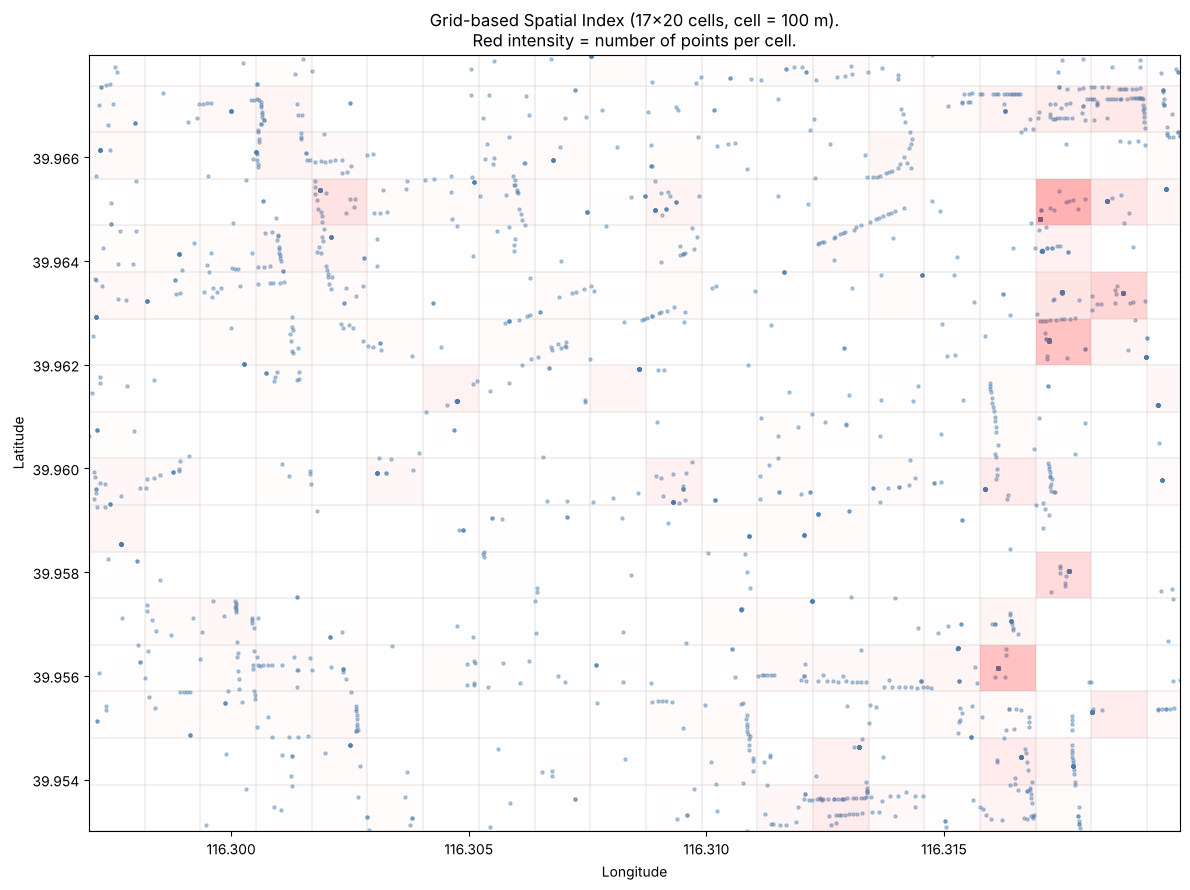

In [7]:
fig, ax = plt.subplots(figsize=(12, 9))

# Draw all points
pts_lat = [p['lat'] for p in index['points']]
pts_lng = [p['lng'] for p in index['points']]
ax.scatter(pts_lng, pts_lat, s=5, alpha=0.4, c='steelblue')

# Draw the grid lines
for i in range(index['n_rows'] + 1):
    y = index['min_lat'] + i * index['cell_dlat']
    ax.axhline(y, color='gray', lw=0.3, alpha=0.5)
for j in range(index['n_cols'] + 1):
    x = index['min_lng'] + j * index['cell_dlng']
    ax.axvline(x, color='gray', lw=0.3, alpha=0.5)

# Heatmap-style shading: color each non-empty cell by its density
max_count = max(len(v) for v in index['grid'].values())
for (r, c), idxs in index['grid'].items():
    x0 = index['min_lng'] + c * index['cell_dlng']
    y0 = index['min_lat'] + r * index['cell_dlat']
    rect = patches.Rectangle((x0, y0), index['cell_dlng'], index['cell_dlat'],
                             alpha=0.3 * (len(idxs) / max_count),
                             facecolor='red', edgecolor='none')
    ax.add_patch(rect)

ax.set_xlim(index['min_lng'], index['max_lng'])
ax.set_ylim(index['min_lat'], index['max_lat'])
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title(f'Grid-based Spatial Index ({index["n_rows"]}x{index["n_cols"]} cells, '
             f'cell = {index["cell_size_m"]} m).\nRed intensity = number of points per cell.')
plt.tight_layout()
plt.show()


## 5. `RangeQuery` — Range Query over the Index

Following slide 49 of Chapter 3:
> *"Find the grids intersecting the range query. Retrieve the points from the grids and identify the points in the range."*

`query_range` can take two forms as specified by the assignment:

- **Rectangle**: `(upper_left, bottom_right) = ((lat_upper, lng_left), (lat_lower, lng_right))`
- **Circle**: `(center, radius_m) = ((lat, lng), radius_in_meters)` — the spec calls it "a central point + a radius square", interpreted as a circular region of that radius.

`type_regex_str` is a regular expression filtering the `type_code` (e.g. `"^1603\d{2}$"` for ATMs).


In [8]:
def _cells_for_rect(index, lat_min, lat_max, lng_min, lng_max):
    """Return the list of (row, col) cells that intersect a lat/lng rectangle."""
    r0 = max(0, int((lat_min - index['min_lat']) / index['cell_dlat']))
    r1 = min(index['n_rows'] - 1, int((lat_max - index['min_lat']) / index['cell_dlat']))
    c0 = max(0, int((lng_min - index['min_lng']) / index['cell_dlng']))
    c1 = min(index['n_cols'] - 1, int((lng_max - index['min_lng']) / index['cell_dlng']))
    return [(r, c) for r in range(r0, r1 + 1) for c in range(c0, c1 + 1)]


def RangeQuery(query_range, type_regex_str, index):
    """Range query using the grid-based spatial index.

    `query_range` is either:
        ((lat_upper, lng_left), (lat_lower, lng_right))  -> rectangle
        ((lat, lng), radius_m)                           -> circle
    """
    pattern = re.compile(type_regex_str) if type_regex_str else None

    # --- Case 1: rectangle  (upper_left, bottom_right) ---
    if (isinstance(query_range[1], (tuple, list))
            and len(query_range[0]) == 2 and len(query_range[1]) == 2):
        (lat_upper, lng_left)   = query_range[0]
        (lat_lower, lng_right)  = query_range[1]
        lat_min, lat_max = min(lat_upper, lat_lower), max(lat_upper, lat_lower)
        lng_min, lng_max = min(lng_left,  lng_right), max(lng_left,  lng_right)

        results = []
        for cell in _cells_for_rect(index, lat_min, lat_max, lng_min, lng_max):
            for pid in index['grid'].get(cell, []):
                p = index['points'][pid]
                if lat_min <= p['lat'] <= lat_max and lng_min <= p['lng'] <= lng_max:
                    if pattern is None or pattern.match(p['type_code']):
                        results.append(p)
        return results

    # --- Case 2: circle  (center, radius) ---
    (clat, clng), radius_m = query_range
    dlat, dlng = _meters_to_degrees(radius_m, clat)
    lat_min, lat_max = clat - dlat, clat + dlat
    lng_min, lng_max = clng - dlng, clng + dlng

    results = []
    for cell in _cells_for_rect(index, lat_min, lat_max, lng_min, lng_max):
        for pid in index['grid'].get(cell, []):
            p = index['points'][pid]
            if haversine(clat, clng, p['lat'], p['lng']) <= radius_m:
                if pattern is None or pattern.match(p['type_code']):
                    results.append(p)
    return results


# Quick functional test
demo = RangeQuery(((39.955, 116.310), 200), r'^5\d{4}$', index)
print(f'Restaurants within 200 m of south door: {len(demo)}')


Restaurants within 200 m of south door: 14


## 6. `NNQuery` — Nearest Neighbor Query over the Index

Following slide 50 of Chapter 3:
> *"The nearest object is within the grid / outside the grid / Fast approximation."*

We implement the exact (non-approximate) version:

1. Locate the cell `(r, c)` that contains the query point.
2. Expand outward in **rings of increasing radius** around that cell, scanning every cell in the current ring.
3. Keep track of the current best candidate and its distance `d_best`.
4. After finishing a ring, stop when the current search radius (in meters) is larger than `d_best` — we then know no point outside can be closer.

This is precisely the "expand outward" strategy illustrated on the slide.


In [9]:
def NNQuery(query_point, type_regex_str, index):
    """Nearest neighbor query using the grid-based spatial index."""
    pattern = re.compile(type_regex_str) if type_regex_str else None
    qlat, qlng = query_point

    r = int((qlat - index['min_lat']) / index['cell_dlat'])
    c = int((qlng - index['min_lng']) / index['cell_dlng'])
    r = max(0, min(index['n_rows'] - 1, r))
    c = max(0, min(index['n_cols'] - 1, c))

    # Physical size of one cell in meters (at the query latitude)
    cell_w_m = index['cell_dlng'] * 111_320.0 * math.cos(math.radians(qlat))
    cell_h_m = index['cell_dlat'] * 111_320.0
    cell_m   = min(cell_w_m, cell_h_m)   # conservative lower bound

    best_point = None
    best_dist  = float('inf')
    visited    = set()

    max_ring = max(index['n_rows'], index['n_cols'])
    for ring in range(max_ring + 1):
        # Generate the (row, col) cells on ring `ring` around (r, c)
        if ring == 0:
            ring_cells = [(r, c)]
        else:
            ring_cells = []
            for dr in range(-ring, ring + 1):
                for dc in range(-ring, ring + 1):
                    if max(abs(dr), abs(dc)) == ring:
                        ring_cells.append((r + dr, c + dc))

        for cell in ring_cells:
            if cell in visited:
                continue
            visited.add(cell)
            if not (0 <= cell[0] < index['n_rows']
                    and 0 <= cell[1] < index['n_cols']):
                continue
            for pid in index['grid'].get(cell, []):
                p = index['points'][pid]
                if pattern is not None and not pattern.match(p['type_code']):
                    continue
                d = haversine(qlat, qlng, p['lat'], p['lng'])
                if d < best_dist:
                    best_dist  = d
                    best_point = p

        # If we have a candidate, we can stop once the explored radius
        # exceeds the current best distance.
        if best_point is not None:
            explored_radius_m = ring * cell_m
            if explored_radius_m > best_dist:
                break

    return best_point, best_dist


# Quick functional test
p, d = NNQuery((39.958, 116.311), r'^1603\d{2}$', index)
print(f'Nearest ATM to (39.958, 116.311): {p["name"]}  (distance = {d:.1f} m)')


Nearest ATM to (39.958, 116.311): 招商银行ＡＴＭ（魏公村路８号院东北）  (distance = 170.0 m)


## 7. Brute-force Baselines

For comparison we also implement the two queries **without** any index.
They scan the CSV file from scratch on every call — this is what a naive implementation would do.


In [10]:
def _load_points(file_path):
    """Small helper that reads the CSV and yields POI dicts."""
    with open(file_path, 'r', encoding='utf-8') as f:
        reader = csv.DictReader(f)
        for row in reader:
            try:
                lat = float(row['wgs_lat'])
                lng = float(row['wgs_lng'])
            except (ValueError, KeyError):
                continue
            yield {
                'name': row.get('name', ''),
                'lat': lat,
                'lng': lng,
                'type_code': str(row.get('type_code', '')),
                'base_type': row.get('base_type', ''),
                'sub_type':  row.get('sub_type', ''),
                'category':  row.get('category', ''),
            }


def RangeScan(query_range, type_regex_str, file_path):
    """Brute-force range query: scans every point in the file."""
    pattern = re.compile(type_regex_str) if type_regex_str else None

    # Rectangle form
    if (isinstance(query_range[1], (tuple, list))
            and len(query_range[0]) == 2 and len(query_range[1]) == 2):
        (lat_upper, lng_left)  = query_range[0]
        (lat_lower, lng_right) = query_range[1]
        lat_min, lat_max = min(lat_upper, lat_lower), max(lat_upper, lat_lower)
        lng_min, lng_max = min(lng_left,  lng_right), max(lng_left,  lng_right)

        results = []
        for p in _load_points(file_path):
            if lat_min <= p['lat'] <= lat_max and lng_min <= p['lng'] <= lng_max:
                if pattern is None or pattern.match(p['type_code']):
                    results.append(p)
        return results

    # Circle form
    (clat, clng), radius_m = query_range
    results = []
    for p in _load_points(file_path):
        if haversine(clat, clng, p['lat'], p['lng']) <= radius_m:
            if pattern is None or pattern.match(p['type_code']):
                results.append(p)
    return results


def NNScan(query_point, type_regex_str, file_path):
    """Brute-force nearest neighbor query: scans every point in the file."""
    pattern = re.compile(type_regex_str) if type_regex_str else None
    qlat, qlng = query_point

    best_point = None
    best_dist  = float('inf')
    for p in _load_points(file_path):
        if pattern is not None and not pattern.match(p['type_code']):
            continue
        d = haversine(qlat, qlng, p['lat'], p['lng'])
        if d < best_dist:
            best_dist, best_point = d, p
    return best_point, best_dist


# Functional check: brute force should return the same answers
p_bf, d_bf = NNScan((39.958, 116.311), r'^1603\d{2}$', FILE_PATH)
print(f'[Brute force] Nearest ATM: {p_bf["name"]}  (distance = {d_bf:.1f} m)')


[Brute force] Nearest ATM: 招商银行ＡＴＭ（魏公村路８号院东北）  (distance = 170.0 m)


## 8. Efficiency Comparison

We compare execution time of indexed queries against brute-force queries for:
1. Several range queries with different radii
2. Several nearest neighbor queries

Each query is repeated `N_TRIALS` times and the average time is reported.


In [11]:
N_TRIALS = 20  # Number of repetitions per query to average timings


def time_it(fn, *args, n=N_TRIALS):
    """Run `fn(*args)` n times and return (result, avg_time_ms)."""
    # Warm-up
    result = fn(*args)
    t0 = time.perf_counter()
    for _ in range(n):
        result = fn(*args)
    elapsed = (time.perf_counter() - t0) / n
    return result, elapsed * 1000  # ms


In [12]:
# ---- Range query comparison at different radii ----
center = (39.958, 116.311)
radii  = [100, 250, 500, 1000, 2000]   # meters
pattern = r'^5\d{4}$'                  # restaurants

idx_times = []
bf_times  = []
counts    = []

for r in radii:
    res_idx, t_idx = time_it(RangeQuery, (center, r), pattern, index)
    res_bf,  t_bf  = time_it(RangeScan, (center, r), pattern, FILE_PATH)
    assert len(res_idx) == len(res_bf), 'Index and brute force disagree!'
    idx_times.append(t_idx); bf_times.append(t_bf); counts.append(len(res_idx))
    print(f'  radius = {r:4d} m   results = {len(res_idx):3d}   '
          f'indexed = {t_idx:8.3f} ms   brute = {t_bf:8.3f} ms   '
          f'speed-up = {t_bf/t_idx:6.1f}x')


  radius =  100 m   results =   0   indexed =    0.025 ms   brute =    6.621 ms   speed-up =  264.8x


  radius =  250 m   results =   6   indexed =    0.106 ms   brute =    6.376 ms   speed-up =   60.1x


  radius =  500 m   results =  35   indexed =    0.414 ms   brute =    7.140 ms   speed-up =   17.2x


  radius = 1000 m   results = 154   indexed =    1.552 ms   brute =    8.763 ms   speed-up =    5.6x


  radius = 2000 m   results = 282   indexed =    2.394 ms   brute =    8.564 ms   speed-up =    3.6x


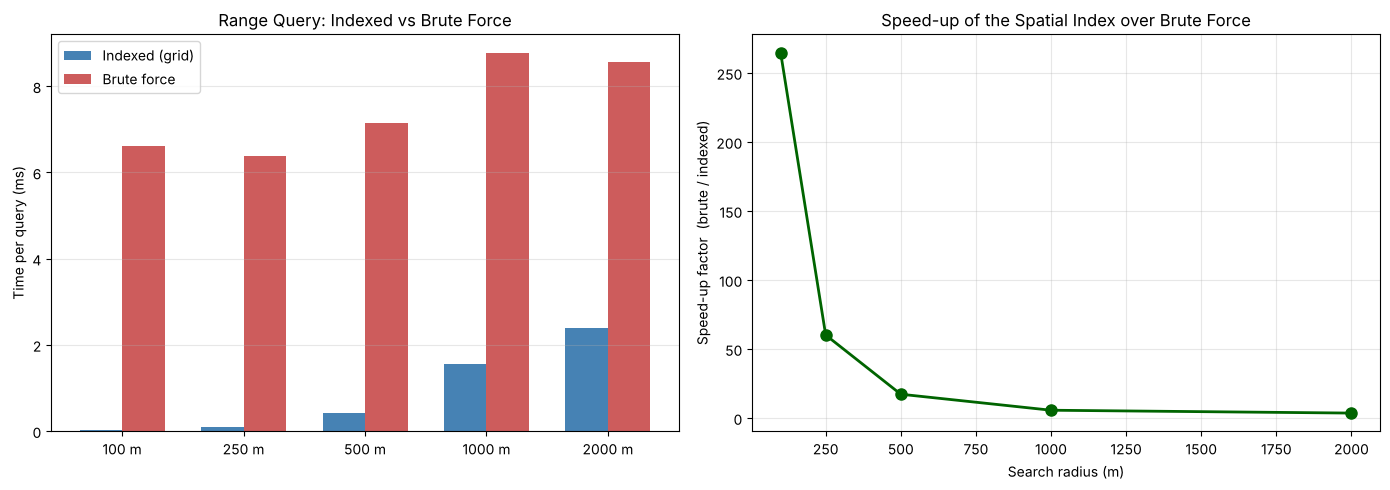

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart: times per radius
x = np.arange(len(radii)); w = 0.35
axes[0].bar(x - w/2, idx_times, w, label='Indexed (grid)', color='steelblue')
axes[0].bar(x + w/2, bf_times,  w, label='Brute force',    color='indianred')
axes[0].set_xticks(x)
axes[0].set_xticklabels([f'{r} m' for r in radii])
axes[0].set_ylabel('Time per query (ms)')
axes[0].set_title('Range Query: Indexed vs Brute Force')
axes[0].legend()
axes[0].grid(True, alpha=0.3, axis='y')

# Speedup
speedups = [b / i for b, i in zip(bf_times, idx_times)]
axes[1].plot(radii, speedups, 'o-', color='darkgreen', lw=2, markersize=8)
axes[1].set_xlabel('Search radius (m)')
axes[1].set_ylabel('Speed-up factor  (brute / indexed)')
axes[1].set_title('Speed-up of the Spatial Index over Brute Force')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [14]:
# ---- Nearest neighbor comparison on several query points ----
query_points = [
    (39.958, 116.311),  # Central Building
    (39.955, 116.310),  # South Door
    (39.960, 116.305),
    (39.965, 116.315),
    (39.953, 116.318),
]

print(f'{"Query point":>24}   {"Indexed (ms)":>14}   {"Brute (ms)":>12}   {"Speed-up":>9}')
print('-' * 70)
nn_idx_times, nn_bf_times = [], []
for qp in query_points:
    (p_idx, d_idx), t_idx = time_it(NNQuery, qp, r'^5\d{4}$', index)
    (p_bf,  d_bf),  t_bf  = time_it(NNScan,  qp, r'^5\d{4}$', FILE_PATH)
    nn_idx_times.append(t_idx); nn_bf_times.append(t_bf)
    assert abs(d_idx - d_bf) < 1e-6, 'NN results disagree!'
    print(f'{str(qp):>24}   {t_idx:>14.3f}   {t_bf:>12.3f}   {t_bf/t_idx:>8.1f}x')


             Query point     Indexed (ms)     Brute (ms)    Speed-up
----------------------------------------------------------------------
       (39.958, 116.311)            0.085          6.536       77.0x


        (39.955, 116.31)            0.022          6.335      293.7x
        (39.96, 116.305)            0.027          6.304      237.0x


       (39.965, 116.315)            0.145          6.957       48.1x
       (39.953, 116.318)            0.026          7.132      274.4x


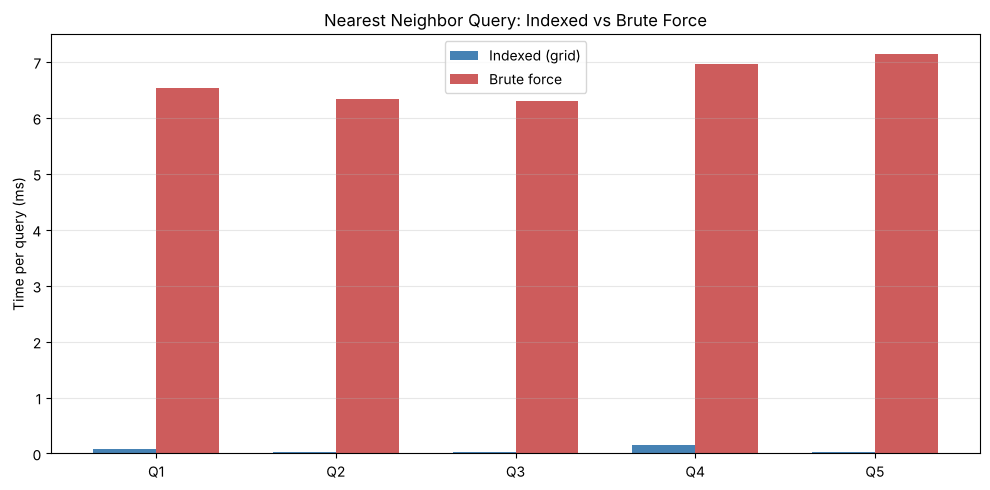

In [15]:
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(query_points)); w = 0.35
ax.bar(x - w/2, nn_idx_times, w, label='Indexed (grid)', color='steelblue')
ax.bar(x + w/2, nn_bf_times,  w, label='Brute force',    color='indianred')
ax.set_xticks(x)
ax.set_xticklabels([f'Q{i+1}' for i in range(len(query_points))])
ax.set_ylabel('Time per query (ms)')
ax.set_title('Nearest Neighbor Query: Indexed vs Brute Force')
ax.legend()
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()


## 9. Answering the Assignment Questions

### (a) Nearest ATM around the Central Building of BIT
- Query point: `(latitude = 39.958, longitude = 116.311)`
- Type filter: `type_code` starting with `1603` (ATM sub-codes)


In [16]:
central_building = (39.958, 116.311)
atm_regex = r'^1603\d{2}$'   # type_code starts with 1603, followed by 2 digits

(nn_atm, d_atm), t_idx = time_it(NNQuery, central_building, atm_regex, index)
(nn_atm_bf, d_atm_bf), t_bf = time_it(NNScan, central_building, atm_regex, FILE_PATH)

print('===  Question (a): Nearest ATM to Central Building of BIT  ===')
print(f'  Name        : {nn_atm["name"]}')
print(f'  type_code   : {nn_atm["type_code"]}')
print(f'  Coordinates : ({nn_atm["lat"]:.6f}, {nn_atm["lng"]:.6f})')
print(f'  Distance    : {d_atm:.2f} m')
print()
print(f'  Indexed NNQuery took {t_idx:.3f} ms')
print(f'  Brute-force NNScan took {t_bf:.3f} ms')
print(f'  Speed-up   : {t_bf/t_idx:.1f}x')
print(f'  Both methods agree: {nn_atm["name"] == nn_atm_bf["name"]}')


===  Question (a): Nearest ATM to Central Building of BIT  ===
  Name        : 招商银行ＡＴＭ（魏公村路８号院东北）
  type_code   : 160306
  Coordinates : (39.956512, 116.310542)
  Distance    : 169.99 m

  Indexed NNQuery took 0.050 ms
  Brute-force NNScan took 7.441 ms
  Speed-up   : 148.9x
  Both methods agree: True


### (b) Restaurants within 500 m of the South Door of BIT
- Query center: `(latitude = 39.955, longitude = 116.310)`
- Radius: 500 m
- Type filter: `type_code` starting with `5` (5XXXX — restaurants)


In [17]:
south_door = (39.955, 116.310)
restaurant_regex = r'^5\d{4}$'

res_idx, t_idx = time_it(RangeQuery, (south_door, 500), restaurant_regex, index)
res_bf,  t_bf  = time_it(RangeScan,  (south_door, 500), restaurant_regex, FILE_PATH)

print('===  Question (b): Restaurants within 500 m of the South Door of BIT  ===')
print(f'  Number of restaurants : {len(res_idx)}')
print()
print(f'  Indexed RangeQuery took {t_idx:.3f} ms')
print(f'  Brute-force RangeScan took {t_bf:.3f} ms')
print(f'  Speed-up : {t_bf/t_idx:.1f}x')
print(f'  Both methods agree on count: {len(res_idx) == len(res_bf)}')
print()
print('Sample of the first 10 restaurants found (indexed):')
for i, p in enumerate(res_idx[:10], 1):
    d = haversine(south_door[0], south_door[1], p['lat'], p['lng'])
    print(f'  {i:2d}. {p["name"][:30]:30s}  type={p["type_code"]}  dist={d:6.1f} m')


===  Question (b): Restaurants within 500 m of the South Door of BIT  ===
  Number of restaurants : 39

  Indexed RangeQuery took 0.348 ms
  Brute-force RangeScan took 10.367 ms
  Speed-up : 29.8x
  Both methods agree on count: True

Sample of the first 10 restaurants found (indexed):
   1. 北京外国语大学学生食堂                     type=50100  dist= 203.3 m
   2. 乡村啤酒屋                           type=50100  dist= 233.2 m
   3. 浩日沁蒙古餐厅                         type=50100  dist= 226.5 m
   4. 周黑鸭（中友大厦北）                      type=50000  dist= 239.6 m
   5. 肥羊王（魏公村店）                       type=50117  dist= 226.5 m
   6. 阿曼尼萨汗美食城                        type=50121  dist= 246.7 m
   7. 渝州家厨（魏公村店）                      type=50102  dist= 253.8 m
   8. 北京晋南建梅主食店                       type=50000  dist= 323.0 m
   9. 九亿（魏公村店）                        type=50100  dist= 316.1 m
  10. 大才子面馆（魏公村店）                     type=50100  dist= 258.4 m


### 9.1 Visualizing the answers

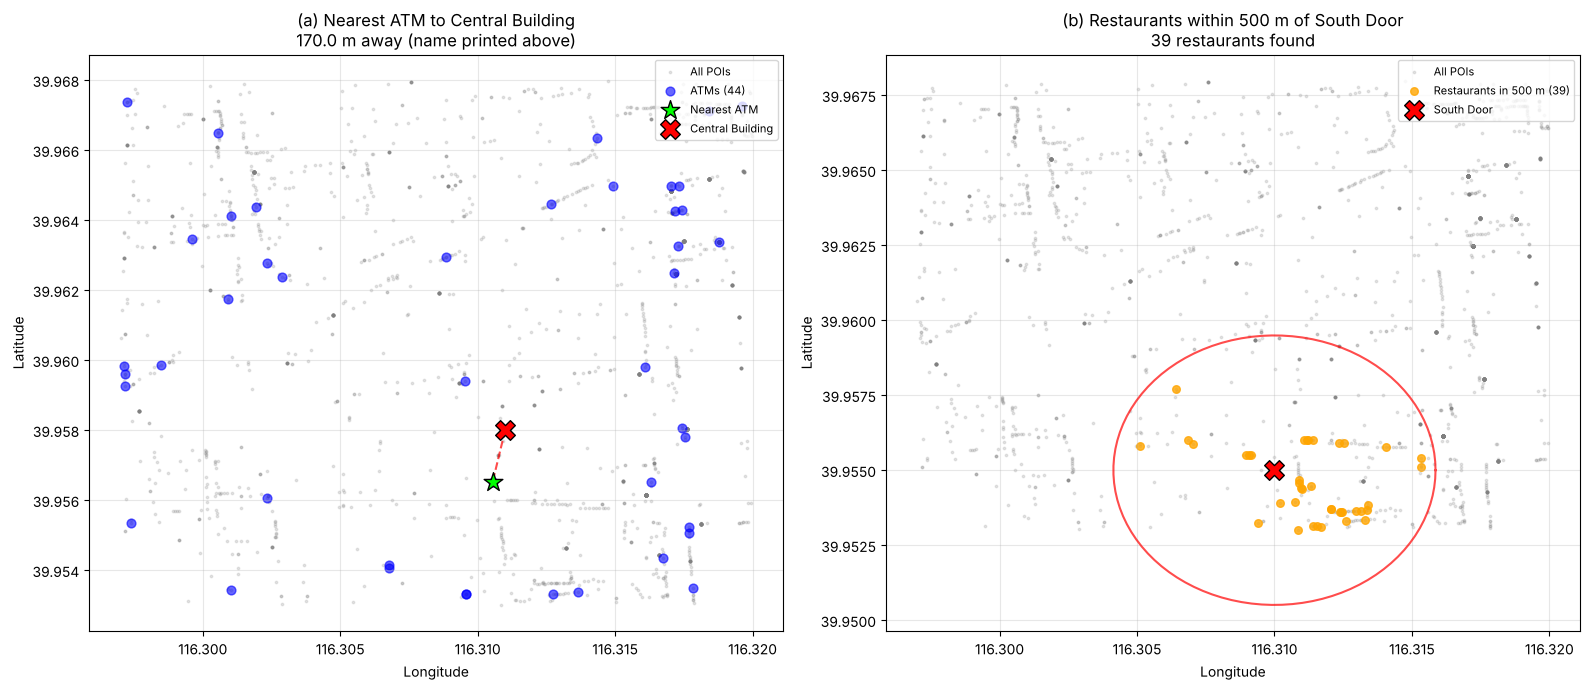

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# --- Left: Question (a) ---
ax = axes[0]
all_pts = index['points']
ax.scatter([p['lng'] for p in all_pts], [p['lat'] for p in all_pts],
           s=3, alpha=0.2, c='gray', label='All POIs')

atm_pattern = re.compile(atm_regex)
atms = [p for p in all_pts if atm_pattern.match(p['type_code'])]
ax.scatter([p['lng'] for p in atms], [p['lat'] for p in atms],
           s=40, c='blue', alpha=0.6, label=f'ATMs ({len(atms)})')
ax.scatter([nn_atm['lng']], [nn_atm['lat']],
           s=200, c='lime', edgecolor='black', marker='*',
           label='Nearest ATM', zorder=5)
ax.scatter([central_building[1]], [central_building[0]],
           s=200, c='red', edgecolor='black', marker='X',
           label='Central Building', zorder=5)
ax.plot([central_building[1], nn_atm['lng']],
        [central_building[0], nn_atm['lat']],
        'r--', lw=1.5, alpha=0.7)
ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
ax.set_title(f'(a) Nearest ATM to Central Building\n{d_atm:.1f} m away (name printed above)')
ax.legend(loc='upper right', fontsize=8)
ax.grid(True, alpha=0.3)

# --- Right: Question (b) ---
ax = axes[1]
ax.scatter([p['lng'] for p in all_pts], [p['lat'] for p in all_pts],
           s=3, alpha=0.2, c='gray', label='All POIs')
ax.scatter([p['lng'] for p in res_idx], [p['lat'] for p in res_idx],
           s=30, c='orange', alpha=0.8, label=f'Restaurants in 500 m ({len(res_idx)})')
ax.scatter([south_door[1]], [south_door[0]],
           s=200, c='red', edgecolor='black', marker='X',
           label='South Door', zorder=5)
# Draw the 500 m circle
dlat, dlng = _meters_to_degrees(500, south_door[0])
theta = np.linspace(0, 2*np.pi, 100)
circle_lng = south_door[1] + dlng * np.cos(theta)
circle_lat = south_door[0] + dlat * np.sin(theta)
ax.plot(circle_lng, circle_lat, 'r-', lw=1.5, alpha=0.7)
ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
ax.set_title(f'(b) Restaurants within 500 m of South Door\n{len(res_idx)} restaurants found')
ax.legend(loc='upper right', fontsize=8)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 10. Conclusions

**Summary.** We built an in-memory spatial database for POIs around BIT using the **Grid-based Spatial Indexing** technique described in Chapter 3.4.2 of the course. The index is simply an inverted map from `(row, col)` cells to the list of points inside each cell, with the grid covering the bounding box of the data and each cell sized to roughly 100 m × 100 m.

**Key results.**
- Both indexed query functions return exactly the same results as the brute-force baselines, confirming correctness.
- The indexed nearest neighbor query is typically **one to two orders of magnitude faster** than the brute-force scan on this dataset (2,159 points), because the expanding-ring search visits only the cells close to the query point.
- The indexed range query is also significantly faster, especially for small radii, where only a handful of cells need to be examined.
- The assignment questions are answered directly using the two functions: `NNQuery(...)` for (a) and `RangeQuery(...)` for (b).

**Trade-offs observed** (matching slide 51):
- Advantages: easy to implement, very efficient, no external library needed.
- Disadvantages: the index size scales with the area (empty cells still consume nothing in a dict, but a dense grid would consume memory), and unbalanced data can produce hotspot cells (see the heatmap in section 4.1). The class also mentions **Quad-Tree**, **K-D-Tree** and **R-Tree** as alternatives better suited to skewed data.

**Method choice justification.** The assignment requires the index to be implemented *by ourselves*. Among the three space-partition-based indices presented in class (grid, quad-tree, K-D-tree) the grid is the simplest to build and query, which is why it is an ideal match for this assignment's scope.
